В этом блокноте содержится код для обучения полносвязной нейронной сети для бинарной классификации. Здесь будет всего два класса: одуванчики и трава.

### Создание набора данных

In [1]:
!wget --no-check-certificate \
    https://github.com/btphan95/simple-cnn/blob/master/train.zip?raw=true \
    -O /tmp/train.zip

--2023-02-17 19:51:02--  https://github.com/btphan95/simple-cnn/blob/master/train.zip?raw=true
Resolving github.com (github.com)... 140.82.121.3
Connecting to github.com (github.com)|140.82.121.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://github.com/btphan95/simple-cnn/raw/master/train.zip [following]
--2023-02-17 19:51:02--  https://github.com/btphan95/simple-cnn/raw/master/train.zip
Reusing existing connection to github.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/btphan95/simple-cnn/master/train.zip [following]
--2023-02-17 19:51:02--  https://raw.githubusercontent.com/btphan95/simple-cnn/master/train.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 11

In [2]:
!wget --no-check-certificate \
    https://github.com/btphan95/simple-cnn/blob/master/valid.zip?raw=true \
    -O /tmp/valid.zip

--2023-02-17 19:51:08--  https://github.com/btphan95/simple-cnn/blob/master/valid.zip?raw=true
Resolving github.com (github.com)... 140.82.121.3
Connecting to github.com (github.com)|140.82.121.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://github.com/btphan95/simple-cnn/raw/master/valid.zip [following]
--2023-02-17 19:51:08--  https://github.com/btphan95/simple-cnn/raw/master/valid.zip
Reusing existing connection to github.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/btphan95/simple-cnn/master/valid.zip [following]
--2023-02-17 19:51:08--  https://raw.githubusercontent.com/btphan95/simple-cnn/master/valid.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 19

Далее написан код для использования библиотеки os, эта библиотека нужна для организации доступа к файловой системе. Еще одна нужная нам библиотека zipfile, она позволяет распаковывать данные.

In [3]:
import os
import zipfile

local_zip = '/tmp/train.zip'
zip_ref = zipfile.ZipFile(local_zip, 'r')
zip_ref.extractall('/tmp')
local_zip = '/tmp/valid.zip'

zip_ref = zipfile.ZipFile(local_zip, 'r')
zip_ref.extractall('/tmp')
zip_ref.close()

Содержимое .zip извлекается в каталог `/tmp/train`, каждый из которых, в свою очередь, содержит подкаталоги `dandelion` и `grass`.

Класс [ImageGenerator](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator) будет использоваться для автоматического создания нашего набора данных из этого каталога, используя подкаталоги для классов.

Определяем каждый из подкаталогов:

In [4]:
# Directory with our training dandelion pictures
train_dandelion_dir = os.path.join('/tmp/train/dandelion')

# Directory with our training grass pictures
train_grass_dir = os.path.join('/tmp/train/grass')

# Directory with our validation dandelion pictures
valid_dandelion_dir = os.path.join('/tmp/valid/dandelion')

# Directory with our validation grass pictures
valid_grass_dir = os.path.join('/tmp/valid/grass')

Далее мы можем посмотреть, как выглядят имена файлов в каталогах для обучения `dandelion` и `grass`:

In [5]:
train_dandelion_names = os.listdir(train_dandelion_dir)
print(train_dandelion_names[:10])

train_grass_names = os.listdir(train_grass_dir)
print(train_grass_names[:10])

validation_dandelion_hames = os.listdir(valid_dandelion_dir)
print(validation_dandelion_hames[:10])

validation_grass_names = os.listdir(valid_grass_dir)
print(validation_grass_names[:10])

['00000464.jpg', '00000272.jpg', '00000428.jpg', '00000423.jpg', '00000416.jpg', '00000457.jpg', '00000028.jpg', '00000299.jpg', '00000482.jpg', '00000096.jpg']
['00000464.jpg', '00000272.jpg', '00000428.jpg', '00000423.jpg', '00000416.jpg', '00000457.jpg', '00000028.jpg', '00000299.jpg', '00000482.jpg', '00000096.jpg']
['00000028.jpg', '00000082.jpg', '00000076.jpg', '00000012.jpg', '00000088.jpg', '00000085.jpg', '00000036.jpg', '00000003.jpg', '00000024.jpg', '00000084.jpg']
['00000028.jpg', '00000012.jpg', '00000036.jpg', '00000003.jpg', '00000024.jpg', '00000014.jpg', '00000013.jpg', '00000018.jpg', '00000007.jpg', '00000002.jpg']


Посмотрим общее количество изображений одуванчиков и травы в каталогах:

In [6]:
print('total training dandelion images:', len(os.listdir(train_dandelion_dir)))
print('total training grass images:', len(os.listdir(train_grass_dir)))
print('total validation dandelion images:', len(os.listdir(valid_dandelion_dir)))
print('total validation grass images:', len(os.listdir(valid_grass_dir)))

total training dandelion images: 500
total training grass images: 499
total validation dandelion images: 92
total validation grass images: 65


Можно также посмотреть несколько фотографий из каталогов. Для этого надо настроить параметры используя библиотеку matplotlib:

In [7]:
%matplotlib inline

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Параметры для нашего вывода; будем выводить изображения в конфигурации 4x4
nrows = 4
ncols = 4

# Индекс для перебора изображений
pic_index = 0

Выведем 8 изображений одуванчика и 8 травы. Перезапуская ячейку, каждый раз вы будете получать новые изображения.

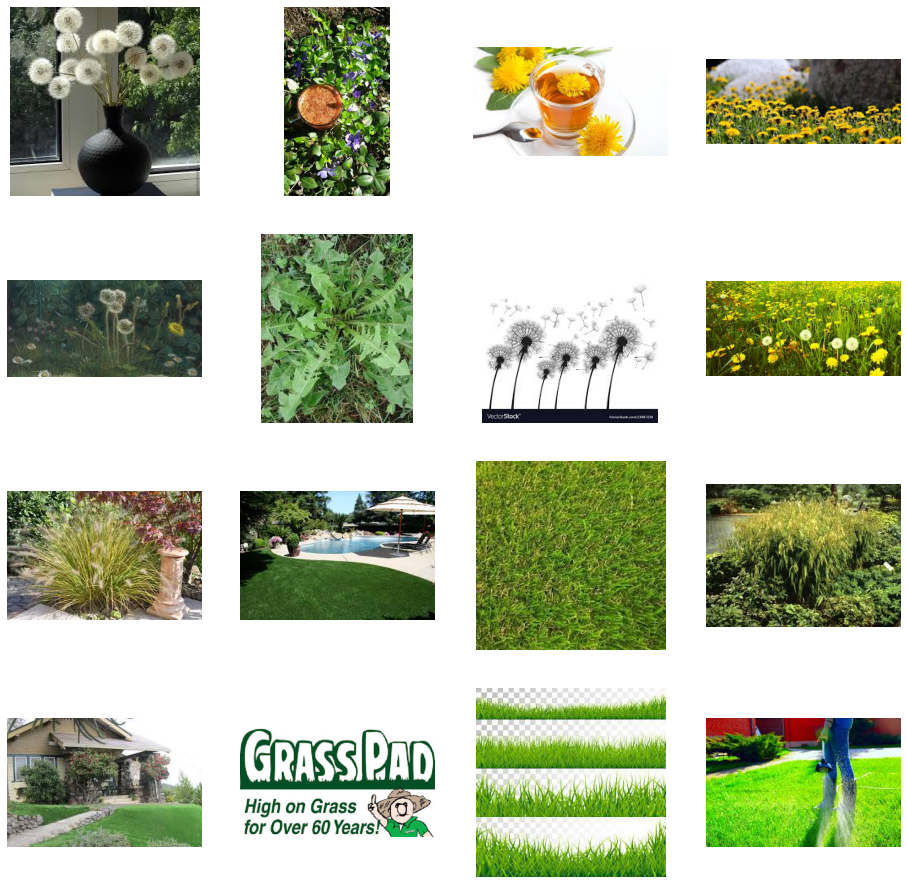

In [8]:
# Настроим matplotlib fig и сделаем так, чтобы вывод соотвествовал 4x4
fig = plt.gcf()
fig.set_size_inches(ncols * 4, nrows * 4)

pic_index += 8
next_dandelion_pic = [os.path.join(train_dandelion_dir, fname) 
                for fname in train_dandelion_names[pic_index-8:pic_index]]
next_grass_pic = [os.path.join(train_grass_dir, fname) 
                for fname in train_grass_names[pic_index-8:pic_index]]

for i, img_path in enumerate(next_dandelion_pic + next_grass_pic):
  # Set up subplot; subplot indices start at 1
  sp = plt.subplot(nrows, ncols, i + 1)
  sp.axis('Off') # Don't show axes (or gridlines)

  img = mpimg.imread(img_path)
  plt.imshow(img)

plt.show()


#### Предварительная обработка данных

Используя класс `keras.preprocessing.image.ImageDataGenerator` можно создать наш набор данных для обучения, проверки и нормализации данных. 

Почему важна нормализация? Данные поступающие в нейронную сеть должны улучшать ее производительность, этого можно добиться масштабированием изображений. Параметр rescale позволяет машстабировать значения пикселей от [0, 255] до [0,1].

В каждом генераторе мы указываем исходный каталог наших изображений, классы, размер входного изображения, размер пакета (сколько изображений обрабатывать одновременно) и режим класса.

In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Масштабирование 1./255
train_datagen = ImageDataGenerator(rescale=1/255)
validation_datagen = ImageDataGenerator(rescale=1/255)

# Поток обучающих изображений партиями по 120 с использованием генератора train_datagen
train_generator = train_datagen.flow_from_directory(
        '/tmp/train/',  # Исходный каталог для обучающих изображений
        classes = ['dandelion', 'grass'],
        target_size=(200, 200),  # Все изображения будут уменьшены до размера 200x200
        batch_size=120,
        # Use binary labels
        class_mode='binary')

# Поток проверочных изображений партиями по 19 с использованием генератора valid_datagen
validation_generator = validation_datagen.flow_from_directory(
        '/tmp/valid/',  # Исходный каталог для обучающих изображений
        classes = ['dandelion', 'grass'],
        target_size=(200, 200),  # Все изображения будут уменьшены до размера 200x200
        batch_size=19,
        # Use binary labels
        class_mode='binary',
        shuffle=False)

Found 999 images belonging to 2 classes.
Found 157 images belonging to 2 classes.


## Создание модели

In [10]:
import tensorflow as tf
import numpy as np
from itertools import cycle

from sklearn import svm, datasets
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from scipy import interp
from sklearn.metrics import roc_auc_score

Воспользуемся слоем Flatten, который будет сглаживать входное изображение. Это изображение далее будет подаваться в следующий полносвязный слой. И так как нам нужна бинарная классификация, крайний слой будет тоже полносвязным с функцией активации sigmoid. На выходе мы получим 0 (одуванчик) или 1 (трава).

In [11]:
model = tf.keras.models.Sequential([tf.keras.layers.Flatten(input_shape = (200,200,3)), 
                                    tf.keras.layers.Dense(128, activation=tf.nn.relu), 
                                    tf.keras.layers.Dense(1, activation=tf.nn.sigmoid)])

In [ ]:
# Еще конфигурация на поэксперементировать, вы вольны делать как вам угодно

'''model = tf.keras.models.Sequential([tf.keras.layers.Conv2D(16, (3,3), activation='relu', input_shape=(200, 200, 3)),
                                    tf.keras.layers.MaxPooling2D(2, 2),
                                    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
                                    tf.keras.layers.MaxPooling2D(2,2),
                                    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
                                    tf.keras.layers.MaxPooling2D(2,2),
                                    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
                                    tf.keras.layers.MaxPooling2D(2,2),
                                    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
                                    tf.keras.layers.MaxPooling2D(2,2),
                                    tf.keras.layers.Flatten(),
                                    tf.keras.layers.Dense(512, activation='relu'),
                                    tf.keras.layers.Dense(1, activation='sigmoid')])'''

Вызываем метод model.summary(). Он отображает топологию нейронной сети. 

In [12]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 120000)            0         
                                                                 
 dense (Dense)               (None, 128)               15360128  
                                                                 
 dense_1 (Dense)             (None, 1)                 129       
                                                                 
Total params: 15,360,257
Trainable params: 15,360,257
Non-trainable params: 0
_________________________________________________________________


Столбец "output shape" показывает преобразование размеров каждого слоя свертки.

Будем использовать binary_crossentropy и оптимизатор Adam. [Адам](https://wikipedia.org/wiki/Stochastic_gradient_descent#Adam) — алгоритм оптимизации, который автоматизирует настройку скорости обучения (в качестве альтернативы мы могли бы также использовать [RMSProp](https://wikipedia.org/wiki/Stochastic_gradient_descent#RMSProp) или [Adagrad](https://developers.google.com/machine-learning/glossary/#AdaGrad)). Мы добавим точность в «метрики», чтобы модель контролировала точность во время обучения.

In [13]:
model.compile(optimizer = tf.optimizers.Adam(),
              loss = 'binary_crossentropy',
              metrics=['accuracy'])

### Обучение
Возьмем 15 эпох.

Пропишеи steps_per_epoch вместе с batch_size в ImageDataGenerator. Таким образом steps_per_epoch * batch_size = total # общее кличество изображений. 
Например, при обучении, 8 * 120 = 960, что чуть меньше нашего общего количества изображений 999.

Во время обучения точность нашей проверки никогда не превышает точность обучения, и это хорошо.

In [14]:
history = model.fit(train_generator,
      steps_per_epoch=8,  
      epochs=15,
      verbose=1,
      validation_data = validation_generator,
      validation_steps=8)

Epoch 1/15
8/8 [==============================] - 7s 701ms/step - loss: 52.0360 - accuracy: 0.5028 - val_loss: 14.0786 - val_accuracy: 0.6053
Epoch 2/15
8/8 [==============================] - 6s 727ms/step - loss: 10.4062 - accuracy: 0.5165 - val_loss: 3.8326 - val_accuracy: 0.6053
Epoch 3/15
8/8 [==============================] - 6s 677ms/step - loss: 2.0470 - accuracy: 0.6155 - val_loss: 3.3087 - val_accuracy: 0.4079
Epoch 4/15
8/8 [==============================] - 6s 680ms/step - loss: 1.8341 - accuracy: 0.6135 - val_loss: 1.5157 - val_accuracy: 0.6250
Epoch 5/15
8/8 [==============================] - 6s 664ms/step - loss: 1.3962 - accuracy: 0.6598 - val_loss: 1.7826 - val_accuracy: 0.6118
Epoch 6/15
8/8 [==============================] - 7s 845ms/step - loss: 1.1901 - accuracy: 0.6780 - val_loss: 2.3884 - val_accuracy: 0.4539
Epoch 7/15
8/8 [==============================] - 6s 680ms/step - loss: 1.1914 - accuracy: 0.6553 - val_loss: 1.3032 - val_accuracy: 0.6118
Epoch 8/15
8/8 [=

## Accuracy, ROC Curve, и AUC

Оценим точность модели:

In [15]:
model.evaluate(validation_generator)

9/9 [==============================] - 0s 50ms/step - loss: 0.8401 - accuracy: 0.6561


[0.8401105403900146, 0.656050980091095]

Теперь рассчитаем кривую ROC и построим ее.

Сделаем прогнозы на нашем проверочном наборе. При использовании генераторов для прогнозирования необходимо сначала отключить перемешивание (как мы сделали, когда создавали validation_generator) и сбросить генератор:

In [16]:
STEP_SIZE_TEST=validation_generator.n//validation_generator.batch_size
validation_generator.reset()
preds = model.predict(validation_generator,
                      verbose=1)

9/9 [==============================] - 1s 48ms/step


Чтобы создать кривую ROC и AUC, нам нужно вычислить частоту ложноположительных и истинных положительных результатов:

In [17]:
fpr, tpr, _ = roc_curve(validation_generator.classes, preds)

In [18]:
roc_auc = auc(fpr, tpr)

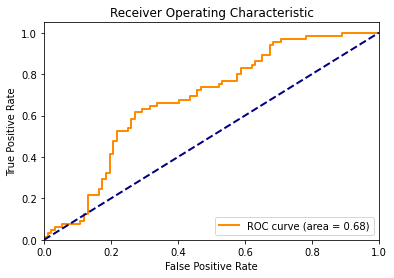

In [19]:
plt.figure()
lw = 2
plt.plot(fpr, tpr, color='darkorange',
         lw=lw, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

Кривая ROC представляет собой кривую вероятности, отображающую соотношение истинно положительных результатов (TPR) к уровню ложноположительных результатов (FPR). На этой кривой диагональная линия представляет собой кривую случайного угадывания, т.е. подбрасывание монеты, поэтому приведенная выше кривая ROC показывает, что модель лучше, чем случайность, справляется с классификацией между одуванчиками и травой.

Точно так же AUC (площадь под кривой), как показано в легенде выше, измеряет, насколько модель способна различать два класса, одуванчики и траву. Чем выше AUC, тем лучше модель при классификации. Она также используется для сравнения различных моделей.

## Потеститурем модель

Далее вы воспользуетесь моделью, чтобы сделать прогнозы. Загрузите изображение и посмотрите на результат.

Saving images.jfif to images (1).jfif
1/1 [==============================] - 0s 81ms/step
[0.]
images.jfif is a dandelion


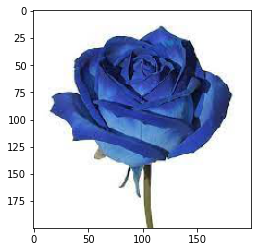

In [21]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files
import keras.utils as image

uploaded = files.upload()

for fn in uploaded.keys():
 
  # predicting images
  path = '/content/' + fn
  img = image.load_img(path, target_size=(200, 200))
  x = image.img_to_array(img)
  plt.imshow(x/255.)
  x = np.expand_dims(x, axis=0)
  images = np.vstack([x])
  classes = model.predict(images, batch_size=10)
  print(classes[0])
  if classes[0]<0.5:
    print(fn + " is a dandelion")
  else:
    print(fn + " is a grass")
 

## Очистка
При запуске следующей ячейки, произойдет завершение работы ядра и освобождение ресурсов памяти:

In [ ]:
import os, signal
os.kill(os.getpid(), signal.SIGKILL)